A simple quantum circuit is a collection of qubits and a list of instructions that act on those qubits. To demonstrate, the following cell creates a new circuit with two new qubits, then displays the circuit's qubits attribute, which is a list of Qubits in order from the least significant bit 
q
0
q 
0
​
  to the most significant bit 
q
n
q 
n
​
 .

In [2]:
from qiskit import QuantumCircuit
qc = QuantumCircuit(2)
qc.qubits
# print(qc)

[<Qubit register=(2, "q"), index=0>, <Qubit register=(2, "q"), index=1>]

In [3]:
from qiskit.circuit import QuantumRegister, ClassicalRegister
qr1 = QuantumRegister(2, "qreg1")  # Create a QuantumRegister with 2 qubits
qr2 = QuantumRegister(1, "qreg2")  # Create a QuantumRegister with 1 qubit
cr1 = ClassicalRegister(3, "creg1")  # Create a ClassicalRegister with 3 cbits

combined_circ = QuantumCircuit(
    qr1, qr2, cr1
)  # Create a quantum circuit with 2 QuantumRegisters and 1 ClassicalRegister
combined_circ.qubits

[<Qubit register=(2, "qreg1"), index=0>,
 <Qubit register=(2, "qreg1"), index=1>,
 <Qubit register=(1, "qreg2"), index=0>]

In [4]:
desired_qubit = qr2[0]  # Qubit 0 of register 'qreg2'

print("Index:", combined_circ.find_bit(desired_qubit).index)
print("Register:", combined_circ.find_bit(desired_qubit).registers)

Index: 2
Register: [(QuantumRegister(1, 'qreg2'), 0)]


Adding an instruction to the circuit appends the instruction to the circuit's data attribute. The following cell output shows data is a list of CircuitInstruction objects, each of which has an operation attribute, and a qubits attribute.

In [5]:
qc.x(0)  # Add X-gate to qubit 0
qc.data

[CircuitInstruction(operation=Instruction(name='x', num_qubits=1, num_clbits=0, params=[]), qubits=(<Qubit register=(2, "q"), index=0>,), clbits=())]

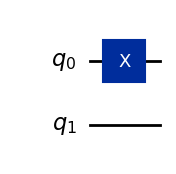

In [6]:
qc.draw("mpl")

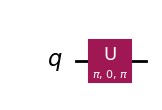

In [7]:
# Draw definition circuit of 0th instruction in `qc`
qc.data[0].operation.definition.draw("mpl")

What is circuit depth?
The depth() of a quantum circuit is a measure of the number of “layers” of quantum gates, executed in parallel, it takes to complete the computation defined by the circuit. Because quantum gates take time to implement, the depth of a circuit roughly corresponds to the amount of time it takes the quantum computer to execute the circuit. Thus, the depth of a circuit is one important quantity used to measure if a quantum circuit can be run on a device.

The rest of this page illustrates how to manipulate quantum circuits.

Build circuits
Methods such as QuantumCircuit.h and QuantumCircuit.cx add specific instructions to circuits. To add instructions to a circuit more generally, use the append method. This takes an instruction and a list of qubits to apply the instruction to. See the Circuit Library API documentation for a list of supported instructions.

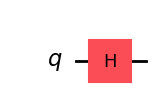

In [8]:
from qiskit.circuit.library import HGate

qc = QuantumCircuit(1)
qc.append(
    HGate(),  # New HGate instruction
    [0],  # Apply to qubit 0
)
qc.draw("mpl")

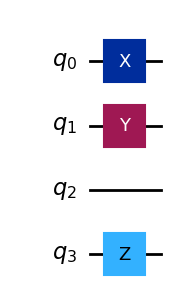

In [9]:
qc_a = QuantumCircuit(4)
qc_a.x(0)

qc_b = QuantumCircuit(2, name="qc_b")
qc_b.y(0)
qc_b.z(1)

# keep qubits (0, 1) of qc_a with same index.
# compose qubits (0,1) of qc_b to qubits (1, 3), respectively, of new composite circuit
combined = qc_a.compose(qc_b, qubits=[1, 3])
combined.draw("mpl")

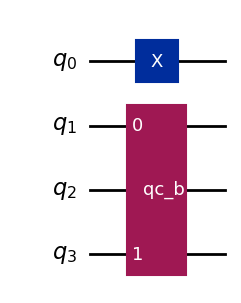

In [10]:
inst = qc_b.to_instruction()
qc_a.append(inst, [1, 3])
qc_a.draw("mpl")

Build a custom circuit using basic gates

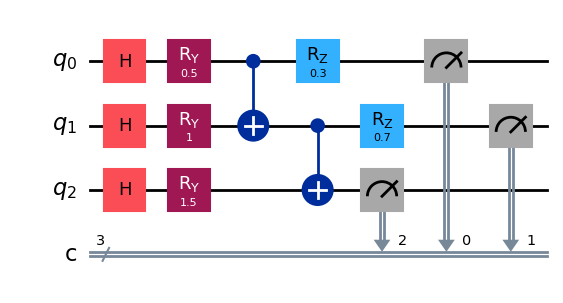

In [11]:
from qiskit import QuantumCircuit

# Create a circuit with 3 qubits and 3 classical bits
qc = QuantumCircuit(3, 3)
# Step 1: Create superposition
qc.h(0)
qc.h(1)
qc.h(2)
# Step 2: Apply quantum rotations
qc.ry(0.5, 0)
qc.ry(1.0, 1)
qc.ry(1.5, 2)

# Step 3: Entangle qubits
qc.cx(0, 1)
qc.cx(1, 2)

# Step 4: Apply phase operations
qc.rz(0.3, 0)
qc.rz(0.7, 1)

# Step 5: Measurement
qc.measure([0, 1, 2], [0, 1, 2])
# Display circuit
qc.draw("mpl")

Create a reusable custom circuit block

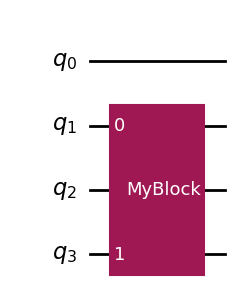

In [12]:
# Create a reusable custom circuit block
from qiskit import QuantumCircuit

def my_custom_block():
    block = QuantumCircuit(2, name="MyBlock")

    block.h(0)
    block.ry(0.5, 1)
    block.cx(0, 1)
    block.rz(0.3, 0)

    return block


# Create the custom block
custom = my_custom_block()

# Create a larger circuit
qc = QuantumCircuit(4)

# Insert custom block into qubits 1 and 3
qc.append(custom.to_instruction(), [1, 3])

qc.draw("mpl")

Build a custom circuit using your own mathematical operation
You can also define a unitary matrix and convert it into a quantum gate.

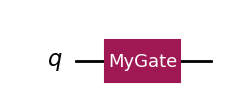

In [13]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.circuit.library import UnitaryGate

# Define a 1-qubit unitary matrix
U = np.array([
    [1, 0],
    [0, 1j]
], dtype=complex)


# Convert matrix into a quantum gate
my_gate = UnitaryGate(U, label="MyGate")

# Create circuit
qc = QuantumCircuit(1)

qc.append(my_gate, [0])

qc.draw("mpl")

In [14]:
print("Number of qubits:", qc.num_qubits)
print("Number of gates:", qc.size())
print("Circuit depth:", qc.depth())
print("Gate operations:", qc.count_ops())

Number of qubits: 1
Number of gates: 1
Circuit depth: 1
Gate operations: OrderedDict([('unitary', 1)])


Measure qubits
Measurements are used to sample the states of individual qubits and transfer the results to a classical register. Note that if you are submitting circuits to a Sampler primitive, measurements are required. However, circuits submitted to an Estimator primitive must not contain measurements.

Qubits can be measured using three methods: measure, measure_all and measure_active. To learn how to visualize measured results, see the Visualize results page.

QuantumCircuit.measure : measures each qubit in the first argument onto the classical bit given as the second argument. This method allows full control over where the measurement result is stored.

QuantumCircuit.measure_all : takes no argument and can be used for quantum circuits without pre-defined classical bits. It creates classical wires and stores measurement results in order. For example, measurement of qubit 
q
i
q 
i
​
  is stored in cbit 
m
e
a
s
i
meas 
i
​
 ). It also adds a barrier before the measurement.

QuantumCircuit.measure_active : similar to measure_all, but measures only qubits that have operations.

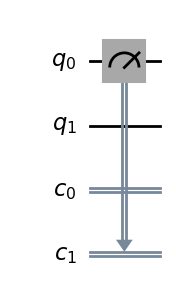

In [15]:
qc1 = QuantumCircuit(2, 2)
qc1.measure(0, 1)
qc1.draw("mpl", cregbundle=False)

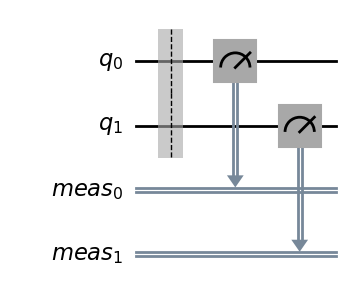

In [16]:
qc2 = QuantumCircuit(2)
qc2.measure_all()
qc2.draw("mpl", cregbundle=False)